In [1]:
import glob, os, shutil, subprocess
os.chdir('/kaggle/working')
shutil.rmtree('/kaggle/working/code', ignore_errors=True)
z = glob.glob('/kaggle/input/**/ma_nguon_cai_tien_deeplog_bgl*.zip', recursive=True)
d = glob.glob('/kaggle/input/**/03_deeplog.py', recursive=True)
if z: subprocess.run(['unzip', '-oq', z[0], '-d', '/kaggle/working'], check=True)
elif d: shutil.copytree(os.path.dirname(d[0]), '/kaggle/working/code')
print(sorted(os.listdir('/kaggle/working/code')))
print('LÀ BẢN V2:', os.path.exists('/kaggle/working/code/08_soft_oov.py') and 'first_unk' in open('/kaggle/working/code/common.py').read())
print('BGL.log:', glob.glob('/kaggle/input/**/BGL*.log', recursive=True))
!pip install -q drain3

['01_parse_bgl.py', '02_make_windows.py', '03_deeplog.py', '04_oov_mapper.py', '05_calibrate.py', '06_classic.py', '07_summary.py', '08_soft_oov.py', 'LENH_CHAY.md', 'common.py', 'requirements.txt', 'run_all.sh']
LÀ BẢN V2: True
BGL.log: ['/kaggle/input/datasets/khnahuyen/bgl-log/BGL.log']
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
pyiceberg 0.12.0 requires cachetools>=5.5, but you have cachetools 4.2.1 which is incompatible.


In [2]:
import glob
LOG = glob.glob('/kaggle/input/**/BGL*.log', recursive=True)[0]
!cd /kaggle/working/code && bash run_all.sh "{LOG}" 42 2>&1 | tee run.log

== 1. Parse (có regex và không regex để so sánh) ==
  500,000 dòng, 130 template, 7s
  1,000,000 dòng, 166 template, 14s
  1,500,000 dòng, 193 template, 21s
  2,000,000 dòng, 489 template, 27s
  2,500,000 dòng, 1,080 template, 33s
  3,000,000 dòng, 1,155 template, 42s
  3,500,000 dòng, 1,188 template, 53s
  4,000,000 dòng, 1,228 template, 62s
  4,500,000 dòng, 1,722 template, 74s
Xong: 4,713,493 dòng hợp lệ, bỏ 34,470 dòng, 2,199 template, 88s -> out/regex
  500,000 dòng, 465 template, 11s
  1,000,000 dòng, 629 template, 29s
  1,500,000 dòng, 716 template, 49s
  2,000,000 dòng, 755 template, 55s
  2,500,000 dòng, 874 template, 60s
  3,000,000 dòng, 1,107 template, 63s
  3,500,000 dòng, 1,291 template, 110s
  4,000,000 dòng, 1,662 template, 227s
  4,500,000 dòng, 2,405 template, 298s
Xong: 4,713,493 dòng hợp lệ, bỏ 34,470 dòng, 2,900 template, 310s -> out/noregex
== 2. Cửa sổ 20 dòng, chia 72/8/20 theo thời gian ==
so_cua_so 235674
so_template_tu_dien 927
train {'so_cua_so': 169685, 'ba

In [3]:
import glob, json, os
R = '/kaggle/working/code/runs/regex_seed42'
for f in sorted(glob.glob('/kaggle/working/code/out/regex/window_stats.json')):
    print('=====', f); print(open(f).read())
print('===== results.md'); print(open(f'{R}/results.md').read())
for f in sorted(glob.glob(f'{R}/metrics_*.json')):
    m = json.load(open(f))
    print('=====', os.path.basename(f)); print(json.dumps({k: v for k, v in m.items() if k != 'val'}, ensure_ascii=False)[:1500])

===== /kaggle/working/code/out/regex/window_stats.json
{
  "so_cua_so": 235674,
  "so_template_tu_dien": 927,
  "train": {
    "so_cua_so": 169685,
    "bat_thuong": 16369,
    "ty_le_bat_thuong_%": 9.647,
    "cua_so_co_template_moi_%": 7.33,
    "template_phan_biet": 1187,
    "template_moi_phan_biet": 260,
    "ty_le_template_moi_%": 21.9
  },
  "val": {
    "so_cua_so": 18853,
    "bat_thuong": 883,
    "ty_le_bat_thuong_%": 4.684,
    "cua_so_co_template_moi_%": 8.86,
    "template_phan_biet": 214,
    "template_moi_phan_biet": 58,
    "ty_le_template_moi_%": 27.1
  },
  "test": {
    "so_cua_so": 47136,
    "bat_thuong": 3004,
    "ty_le_bat_thuong_%": 6.373,
    "cua_so_co_template_moi_%": 49.67,
    "template_phan_biet": 1142,
    "template_moi_phan_biet": 991,
    "ty_le_template_moi_%": 86.78
  }
}
===== results.md
# Kết quả thực nghiệm

## Bảng chính (tập test, ngưỡng chọn trên validation)

| Cấu hình | Ngưỡng | P (%) | R (%) | F1 (%) | Spec (%) | FP | FN | ΔFP | ΔFN |
|---|

C3_hist


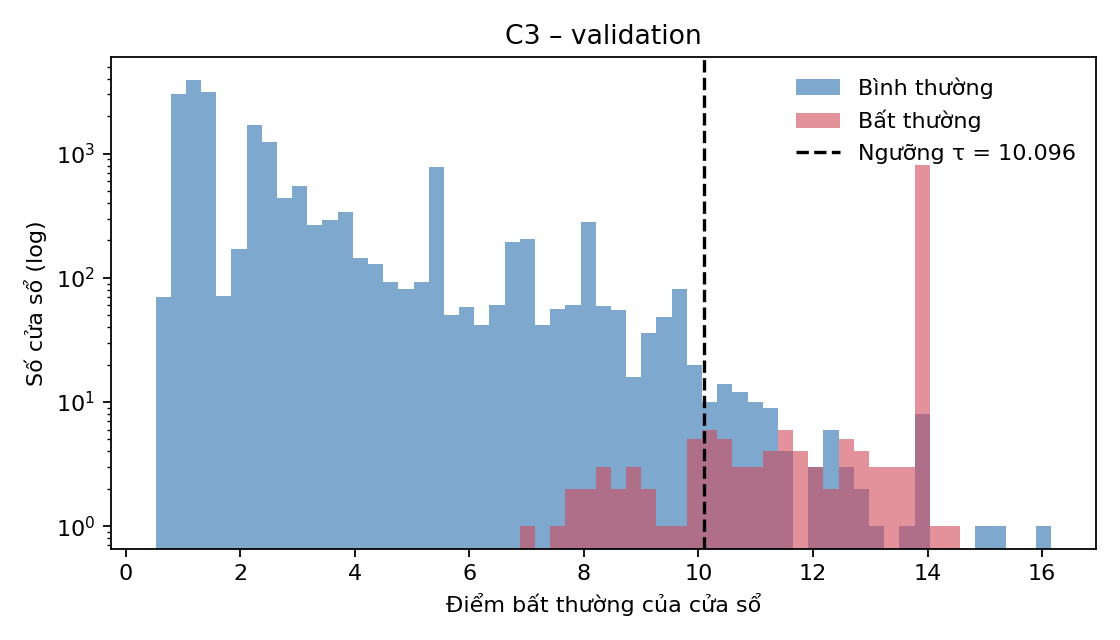

C3_pr


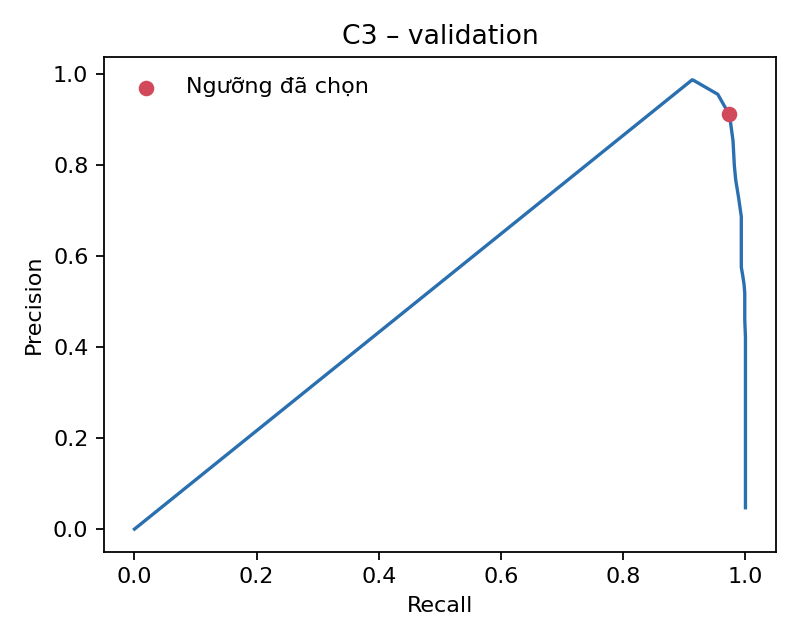

C4_hist


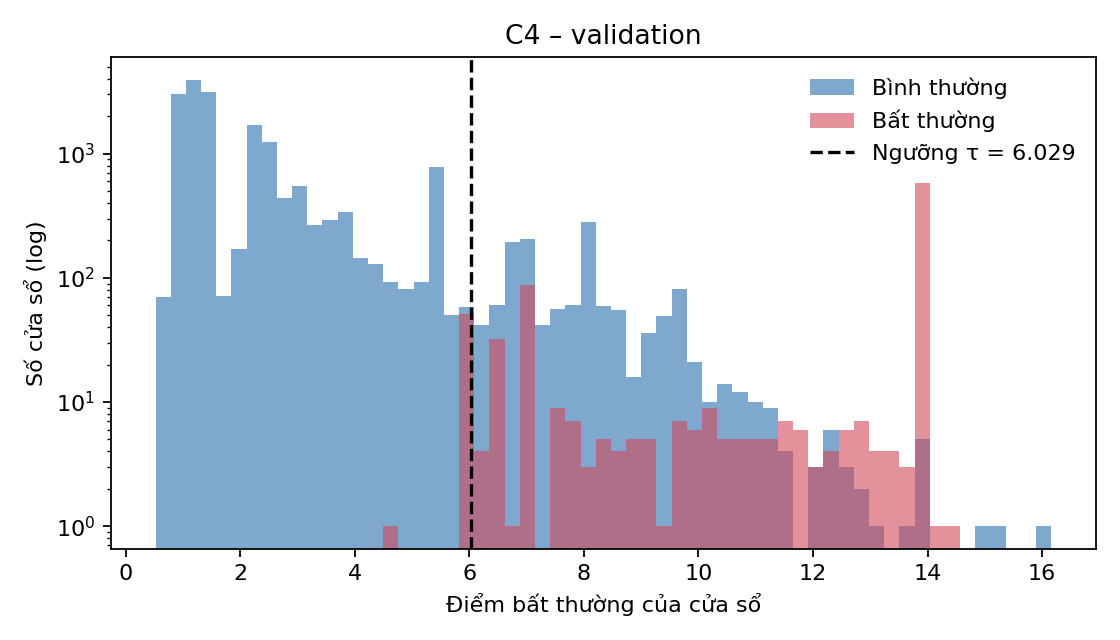

C4_pr


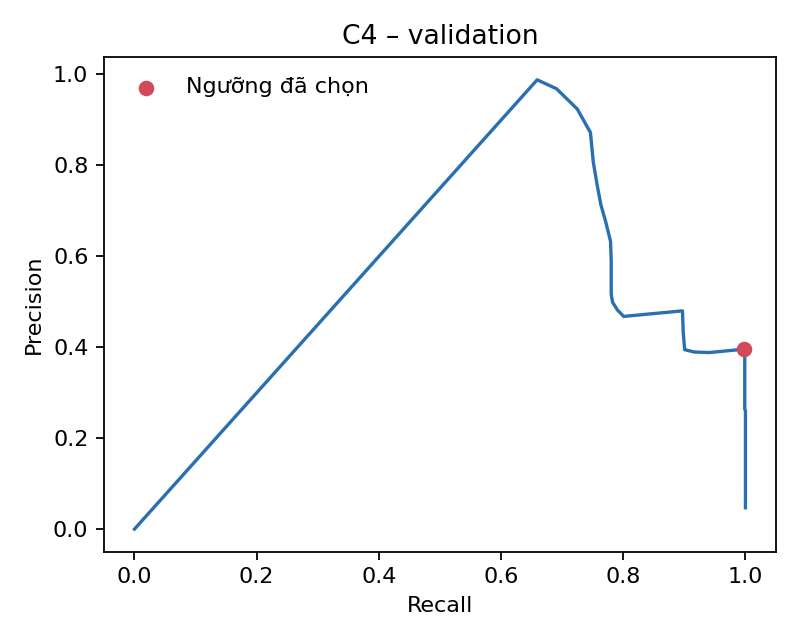

In [4]:
from IPython.display import Image, display
R = '/kaggle/working/code/runs/regex_seed42'
for f in ['C3_hist', 'C3_pr', 'C4_hist', 'C4_pr']:
    print(f); display(Image(f'{R}/{f}.png'))